<a href="https://colab.research.google.com/github/prakashrock0510-ni/project-3_hr_job_placement/blob/main/Project_3_EDA_AND_FE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df=pd.read_csv("/content/Job_placement_cleaneddata.csv")

In [ ]:
df.shape

(50124, 38)

1.Interview score vs job acceptance

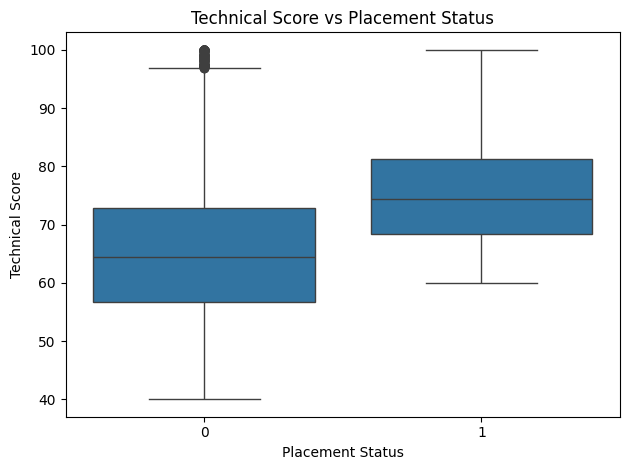

In [ ]:
sns.boxplot(data=df,x="status",y="technical_score")
plt.title("Technical Score vs Placement Status")
plt.xlabel("Placement Status")
plt.ylabel("Technical Score")
plt.tight_layout()
plt.show()

2.Skills match percentage impact on placement

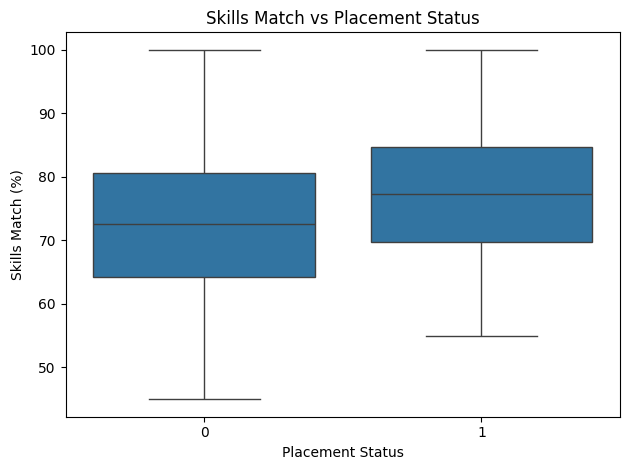

In [ ]:
if "skills_match_percentage" in df.columns:
    sns.boxplot(data=df,x="status",y="skills_match_percentage")
    plt.title("Skills Match vs Placement Status")
    plt.xlabel("Placement Status")
    plt.ylabel("Skills Match (%)")
    plt.tight_layout()
    plt.show()
else:
    print("Skills match column not found.")

Placement Rate by Skills Match:
skills_group
Medium    21.13
High      35.60
Name: status, dtype: float64


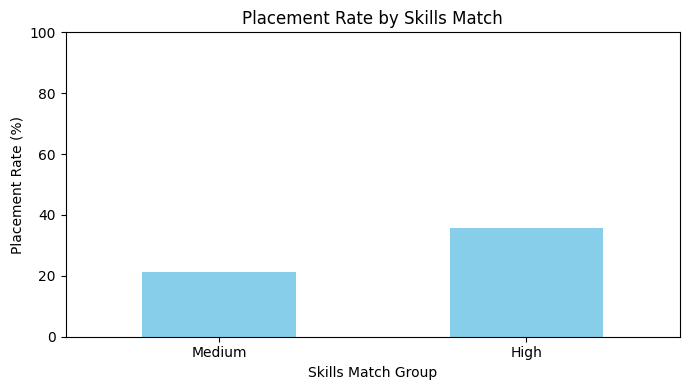

In [ ]:
if "skills_match_percentage" in df.columns:
    df["status"] = pd.to_numeric(df["status"], errors="coerce")
    df["skills_group"] = pd.cut(df["skills_match_percentage"],bins=[0, 40, 70, 100],labels=["Low", "Medium", "High"],include_lowest=True)
    skills_analysis = df.groupby("skills_group",observed=False)["status"].mean() * 100
    skills_analysis = skills_analysis.dropna()
    print("Placement Rate by Skills Match:")
    print(skills_analysis.round(2))
    skills_analysis.plot(kind="bar",figsize=(7, 4),color="skyblue")
    plt.title("Placement Rate by Skills Match")
    plt.xlabel("Skills Match Group")
    plt.ylabel("Placement Rate (%)")
    plt.xticks(rotation=0)
    plt.ylim(0, 100)
    plt.tight_layout()
    plt.show()

3.Company tier vs acceptance rate

Placement Rate by Company Tier:
company_tier
Tier 1    29.95
Tier 2    30.43
Tier 3    30.54
Name: status, dtype: float64


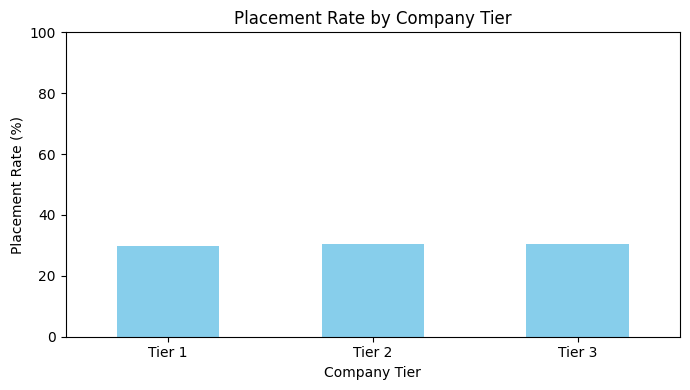

In [ ]:
if "company_tier_Tier 2" in df.columns:
    df["company_tier"] = "Tier 1"
    df.loc[df["company_tier_Tier 2"] == 1, "company_tier"] = "Tier 2"
    df.loc[df["company_tier_Tier 3"] == 1, "company_tier"] = "Tier 3"
    company_analysis = df.groupby("company_tier")["status"].mean() * 100
    print("Placement Rate by Company Tier:")
    print(company_analysis.round(2))
    company_analysis.plot(kind="bar",figsize=(7, 4),color="skyblue")
    plt.title("Placement Rate by Company Tier")
    plt.xlabel("Company Tier")
    plt.ylabel("Placement Rate (%)")
    plt.xticks(rotation=0)
    plt.ylim(0, 100)
    plt.tight_layout()
    plt.show()
else:
    print("Company tier columns not found.")

4.Experience vs placement probability

Placement Rate by Experience:
experience_group
Fresher      13.78
1-2 Years    29.23
3-5 Years    53.68
Name: status, dtype: float64


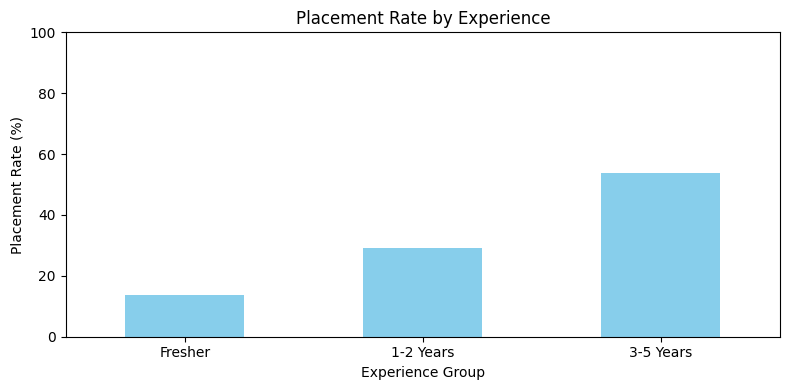

In [ ]:
if "years_of_experience" in df.columns:
    df["status"] = pd.to_numeric(df["status"], errors="coerce")
    df["years_of_experience"] = pd.to_numeric(df["years_of_experience"], errors="coerce")
    df["experience_group"] = pd.cut(df["years_of_experience"],bins=[-1, 0, 2, 5, float("inf")],
        labels=["Fresher", "1-2 Years", "3-5 Years", "Above 5 Years"])
    experience_analysis = df.groupby("experience_group", observed=False)["status"].mean() * 100
    experience_analysis = experience_analysis.dropna().astype(float)
    print("Placement Rate by Experience:")
    print(experience_analysis.round(2))
    if not experience_analysis.empty:
        experience_analysis.plot(kind="bar",figsize=(8, 4),color="skyblue")
        plt.title("Placement Rate by Experience")
        plt.xlabel("Experience Group")
        plt.ylabel("Placement Rate (%)")
        plt.xticks(rotation=0)
        plt.ylim(0, 100)
        plt.tight_layout()
        plt.show()
    else:
        print("No valid placement rates available.")

else:
    print("Experience column not found.")

5.Competition level vs job acceptance

Placement Rate by Competition Level:
competition_level
High      23.80
Low       31.87
Medium    31.93
Name: status, dtype: float64


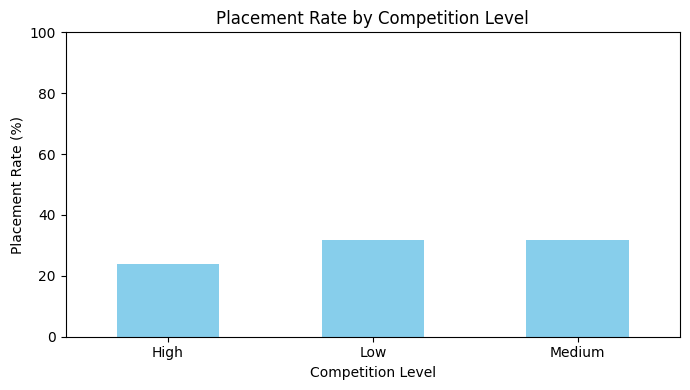

In [ ]:
if "competition_level_Low" in df.columns:
    df["competition_level"] = "High"
    df.loc[df["competition_level_Low"] == 1,"competition_level"] = "Low"
    df.loc[df["competition_level_Medium"] == 1,"competition_level"] = "Medium"
    competition_analysis = df.groupby("competition_level")["status"].mean() * 100
    print("Placement Rate by Competition Level:")
    print(competition_analysis.round(2))
    competition_analysis.plot(kind="bar",figsize=(7, 4),color="skyblue")
    plt.title("Placement Rate by Competition Level")
    plt.xlabel("Competition Level")
    plt.ylabel("Placement Rate (%)")
    plt.xticks(rotation=0)
    plt.ylim(0, 100)
    plt.tight_layout()
    plt.show()

else:
    print("Competition level columns not found.")

6.Correlation analysis among numeric features

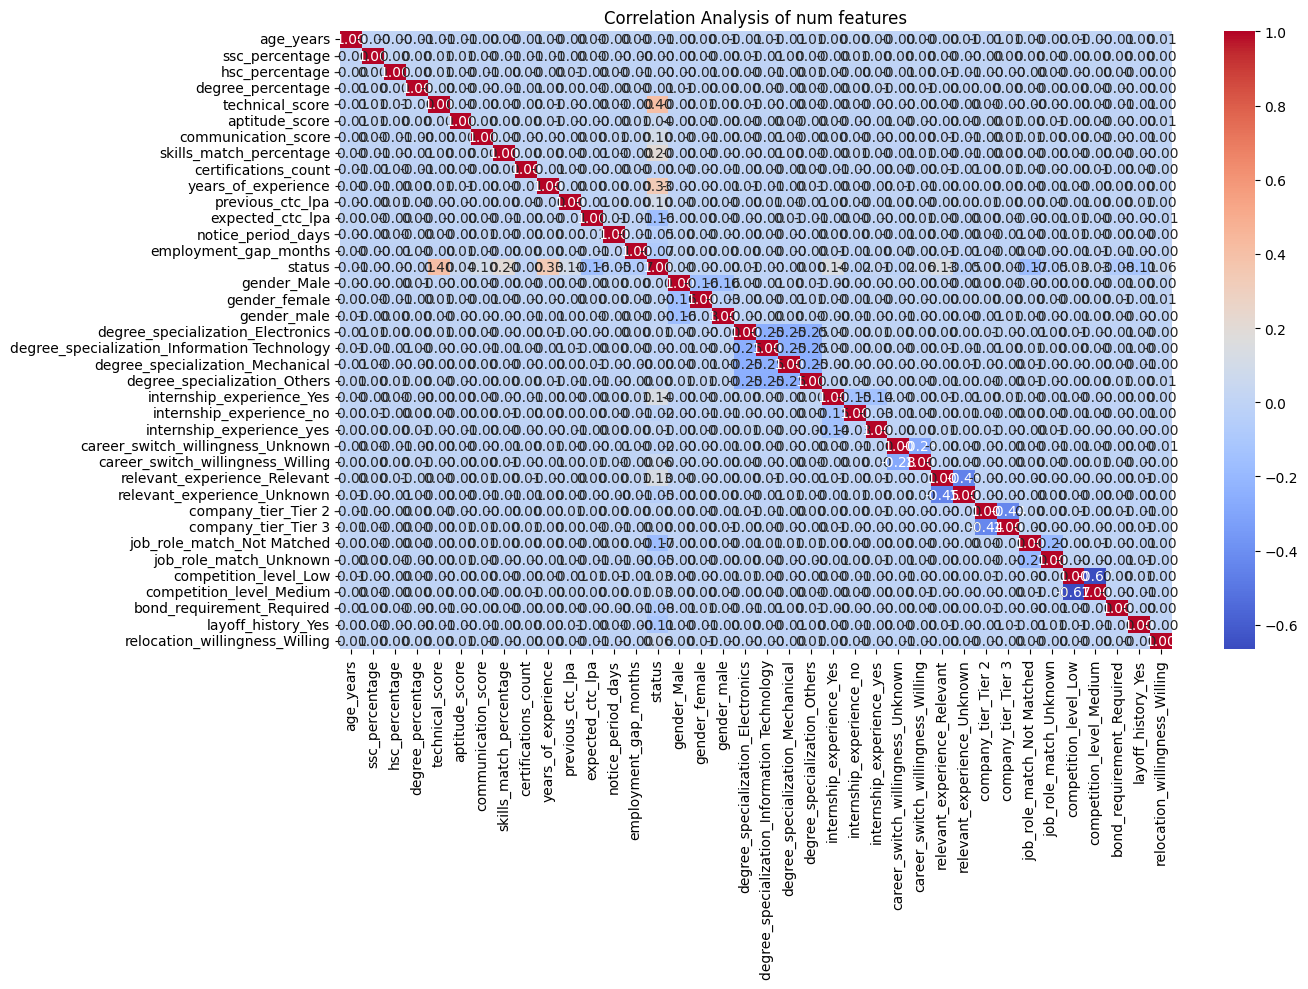

In [ ]:
df["status"] = pd.to_numeric(df["status"], errors="coerce")
numeric_df = df.select_dtypes(include="number")
correlation_matrix = numeric_df.corr()
plt.figure(figsize=(14, 10))
sns.heatmap(correlation_matrix,annot=True,cmap="coolwarm",fmt=".2f")
plt.title("Correlation Analysis of num features")
plt.tight_layout()
plt.show()

FEATURE ENGINEERING

1.Experience category (Fresher / Junior / Senior)

In [ ]:
def experience_category(years):
    if pd.isna(years):
        return "Unknown"
    elif years == 0:
        return "Fresher"
    elif years <= 3:
        return "Junior"
    else:
        return "Senior"
df["experience_category"] = df["years_of_experience"].apply(experience_category)
df["experience_category"].value_counts()

,count
experience_category,
Junior,30082
Fresher,14991
Senior,5051


2.Academic performance bands

In [ ]:
def academic_band(percentage):
    if pd.isna(percentage):
        return "Unknown"
    elif percentage < 60:
        return "Low"
    elif percentage < 75:
        return "Medium"
    else:
        return "High"
df["academic_performance"] = df["degree_percentage"].apply(academic_band)
df["academic_performance"].value_counts()

,count
academic_performance,
Medium,26913
High,22131
Low,1080


3.Skills match level (Low / Medium / High)

In [ ]:
def skills_category(score):
    if pd.isna(score):
        return "Unknown"
    elif score < 60:
        return "Low"
    elif score < 80:
        return "Medium"
    else:
        return "High"
df["skills_match_level"] = df["skills_match_percentage"].apply(skills_category)
print(df["skills_match_level"].value_counts())

skills_match_level
Medium    28420
High      15481
Low        6223
Name: count, dtype: int64


4.Interview performance category

In [ ]:
df["interview_score"] = (df["technical_score"] + df["communication_score"]) / 2
def interview_category(score):
    if pd.isna(score):
        return "Unknown"
    elif score < 50:
        return "Needs Improvement"
    elif score < 75:
        return "Average"
    else:
        return "Good"

df["interview_performance"] = df["interview_score"].apply(interview_category)
print(df["interview_performance"].value_counts())

interview_performance
Average              41885
Good                  7627
Needs Improvement      612
Name: count, dtype: int64
